## Question 1
Suppose we have $n_+$ positive training examples and $n_-$ negative training examples. Let $C_+$ be the center of the positive examples and $C_-$ be the center of the negative examples, i.e. $C_+ = \frac{1}{n_+}\sum_{i: \ y_i = +1} x_i$ and $C_- = \frac{1}{n_-}\sum_{i: \ y_i = -1} x_i$  Consider a simple classifier called CLOSE that classifies a test example $x$ by assigning it to the class whose center is closest.

1) Show that the decision boundary of the CLOSE classifier is a linear hyperplane of the form $sign(\omega\cdot x + b)$. COmpute the values of $\omega$ and $b$ in terms of $C_+$ and $C_-$.

**Answer**:
The classifier assigns $x$ to the positive class when $x$ is close to $C_+$, and assigns to the negative class if it is close to $C_-$. Formally, if $|x-C_+| < |x-C_-|$, it assigns the data to positive class and if $|x-C_+| > |x-C_-|$ it assigns it to the negative class.

Without loss of generality, we take this inequality:
$
|x-C_+| < |x-C_-| \rightarrow |x-C_+|^2 < |x-C_-|^2 \rightarrow  |x-C_-|^2 - |x-C_+|^2 > 0
$

The above result is the classifier's sign function. We should show that this sign function is linear with respect to $x$:

$
(x.x - 2C_-.x + ||C_-||^2) - (x.x -2C_+.x + ||C_-||^2) \rightarrow 2(C_+ - C_-).x +(||C_-||^2 - ||C_+||^2)
$

Therefore, 

$
w = 2(C_+ - C_-)
$

$
b = ||C_-||^2 - ||C_+||^2
$

2) Recall that the weight vector can be written as a linear combination of all the training examples: $\omega = \sum_{i=1}^{n_++n_-}\alpha_i \cdot y_i \cdot x_i$. Compute the dual weights ($\alpha$'s). How many of the training examples are support vectors?

**Answer**:

$
w = 2(C_+ - C_-) = 2(\frac{1}{n_+}\sum_{i: \ y_i = +1} x_i - \frac{1}{n_-}\sum_{i: \ y_i = -1} x_i) \rightarrow 2(\frac{1}{n_+}\sum_{i} x_i.y_i - \frac{1}{n_-}\sum_{i} x_i.y_i) = \sum_{i} \frac{2}{n_+}.x_i.y_i - \sum_{i} \frac{2}{n_-}.x_i.y_i
$

$\alpha_i = \frac{2}{n_+}$  if and only if  $y_i = +1$

$\alpha_i = \frac{2}{n_-}$  if and only if  $y_i = -1$

According to the problem's assumption, we take $C_+$ and $C_-$ as the class representatives. Therefore, every arbitrary points in each class can be a support vector. In a normal SVM, we have only a few points to determine the margin. But here in this example, having $C_+$ and $C_-$ as the class representatives makes every point in each calss as a support vector. So, all $n_+$ and $n_-$ training examples are support vectors.

## Question 2
Suppose we use the following radial basis function (RBF) kernel: $K(x_i, x_j) = exp(-1/2||x_i-x_j||^2)$, which has some implicit unknown mapping $\phi(x)$.


1) Prove that the mapping $\phi(x)$ corresponding to RBF kernel has infinite dimensions.
**Answer**:

Brief explanation: kernel is a function $K(x, x')$ that equals a dot product in some feature space: $K(x, x') = \phi(x)^T\phi(x')$. It takes two inputs in the original space and returns one number, their similarity measured after mapping both into the feature space. The feature space need not be written down; it only has to exist. The SVM still finds a hyperplane, but in feature space. Mapped back to the original space, that hyperplane can be a circle, a curve, or a more complex shape, as shown on slide 67 (SVM lecture). On the slide 72 of SVM lecture, it is explicitly mentioned that the $\phi(x)$ has infinite dimension. But we did not go through the proof of it. However, the tutor mentioned **Taylor Expansion**, so I use it to expand the formula $K(x, x')$.

$$
K(x_i, x_j) = \exp\!\Big(-\tfrac{1}{2}\|x_i\|^2 + x_i^Tx_j - \tfrac{1}{2}\|x_j\|^2\Big) = e^{-\frac{1}{2}\|x_i\|^2}\cdot e^{x_i^Tx_j}\cdot e^{-\frac{1}{2}\|x_j\|^2} \quad (1)
$$  (1)

Taylor expansion formula:

$
e^z = \sum \frac{z^k}{k!}
$
(2)

The first factor depends only on $x_i$ and the last only on $x_j$. Only the middle factor couples the two points. The Taylor expansion formula on the middle facor, we can rewrite (1) using (2): 

$$
e^{x_i^Tx_j} = \sum_{k=0}^{\infty} \frac{(x_i^Tx_j)^k}{k!} \quad (3)
$$

If $x_i, x_j$ are scalars, then $(x_ix_j)^k = x_i^k x_j^k$, and each term splits into a part depending only on $x_i$ times the same part depending only on $x_j$:
$$
\frac{(x_ix_j)^k}{k!} = \frac{x_i^k}{\sqrt{k!}}\cdot\frac{x_j^k}{\sqrt{k!}}
$$

Substituting into (1):

$$
K(x_i, x_j) = \sum_{k=0}^{\infty} \Big(e^{-\frac{1}{2}x_i^2}\frac{x_i^k}{\sqrt{k!}}\Big) \Big(e^{-\frac{1}{2}x_j^2}\frac{x_j^k}{\sqrt{k!}}\Big) = \phi(x_i)^T\phi(x_j)
$$

$$
\phi(x) = e^{-\frac{1}{2}x^2}\left[\,1,\ x,\ \frac{x^2}{\sqrt{2!}},\ \frac{x^3}{\sqrt{3!}},\ \dots\right]^T
$$

$\phi(x)$ has one coordinate for every $k = 0, 1, 2, \dots$, so it has infinitely many dimensions.

2) Prove that for any two input examples $x_i$ and $x_j$, the squared Euclidean distance of their corresponding points in the higher-dimensional space defined by $\phi$ is less than 2, i.e. $||\phi(x_i) - \phi(x_j)||^2 \leq 2$.

**Answer**:

Since $\phi$ is infinite-dimensional, I express the distance through dot products and replace each with the kernel $K(x, x') = \phi(x)^T\phi(x')$.

$$
||\phi(x_i) - \phi(x_j)||^2 = \phi(x_i)^T\phi(x_i) - 2\phi(x_i)^T\phi(x_j) + \phi(x_j)^T\phi(x_j) = K(x_i, x_i) - 2K(x_i, x_j) + K(x_j, x_j)
$$

For the RBF kernel, $K(x, x) = \exp(-\frac{1}{2}||x - x||^2) = e^0 = 1$, so

$$
||\phi(x_i) - \phi(x_j)||^2 = 2 - 2\exp\left(-\frac{1}{2}||x_i - x_j||^2\right)
$$

The above formula clearly shows the it is upper bounded by 2.

## Question 3

The decision boundary of a SVM with a kernel function (via implicit feature mapping $\phi(.)$) is defined as follows:
$$
\omega \cdot \phi(x) + b = \sum_{i \in SV} y_i \alpha_i K(x_i, x) + b = f(x; \alpha, b),
$$
where $\omega$ and $b$ are parameters of the decision boundary in the feature space $\phi$ defined by the kernel function $K$, SV is the set of support vectors and $\alpha_i$ is the dual weight of the $i^{th}$ support vector.
Let us assume that we use the radial basis function (RBF) kernel $K(x_i, x_j) = \mathrm{exp}(-\frac{1}{2}||x_i-x_j||^2)$; also assume that the training examples are linearly separable in the feature space $\phi$ and SVM finds a decision boundary that perfectly separates the training examples. If we choose a testing example $x_{far}$ that is far away from any training instance $x_i$ (distance
here is measured in the original feature space $\mathbb{R}^d$). Prove that $f(x_{far}; \alpha, b) \approx b$.

**Answer**:

In a simple words, the problem is trying to imply that, if we have a test data point which is far from the training ones, the only parameter that affects the result of the classification for this new datapoint is $b$.

Suppose we select $x_{far}$ and we know that its distance from all training data points are very large:
$K(x_{far}, x_j) = \mathrm{exp}(-\frac{1}{2}||x_{far} - x_j||^2)$. At the same time, we know that after the training process, $\alpha_i$ is fixed. We know (according to question 2) that the upper bound for $\mathrm{exp}(-\frac{1}{2}||x_{far} - x_j||^2)$ is $e^{-\frac{||x_{far} - x_j||^2}{2}}$

$$
\mathrm{exp}(-\frac{1}{2}||x_{far} - x_j||^2) \leq e^{-\frac{||x_{far} - x_j||^2}{2}}
$$

If we reproduce the function $f$ from the above inequality, we have:

$$
(\mathrm{\sum{\alpha_i}})\mathrm{exp}(-\frac{1}{2}||x_{far} - x_j||^2) \leq (\mathrm{\sum{\alpha_i}})e^{-\frac{||x_{far} - x_j||^2}{2}}
$$

if $|x_{far} - x_j||^2 \rightarrow \infty$ then $f(x_{far}; \alpha, b) - b| \rightarrow 0$. This means $f(x_{far}; \alpha, b) \approx b$

## Question 4
Prove or disprove: The function $K(x_i, x_j) = - \langle x_i, x_j \rangle$ is a valid kernel.

**Answer**:

It is not a valid kernel. Because, according to the slide presentation, a kernel is defind as follow:

$$
K(x_i, x_j) = \phi(x_i)^T \phi(x_j)
$$

A vector's dot product with itself is never negative. If we take $x_i = x_j = x$, then $K(x, x) = \phi(x)^T \phi(x) = ||\phi(x)||^2 \ge 0$

## Question 5
You are provided with n training examples: $(x_1; y_1); (x_2; y_2); \dots ; (x_n; y_n)$, where $x_i$ is the input example, $y_i$ is the class label ($+1$ or $-1$). The teacher gave you some additional information by specifying the costs for different mistakes $C_+$ and $C_−$, where $C_+$ and $C_−$ stand for
the cost of misclassifying a positive and negative example respectively. How will you modify the Soft-margin SVM formulation to be able to leverage this extra information? Please justify your answer.

**Answer**:

Generally, in SVM, we have to have $min(w^Tw)$ such that $y_i(w^Tx_i + b) \ge 1$. For soft margin, we have to consider the mistakes in our optimization formula:

$min(w^Tw) + \lambda(C_- + C_+)$ such that $y_i(w^Tx_i + b) \ge 1 - C_i$

## Question 6
You are provided with n training examples: $(x_1; y_1); (x_2; y_2); \dots ; (x_n; y_n)$, where $x_i$ is the input example, $y_i$ is the class label ($+1$ or $-1$). Suppose $n$ is very large (say in the order of
millions). In this case, standard SVM training algorithms will not scale due to large training set. We want to devise a solution based on "Coarse-to-Fine" framework of problem solving. The basic idea is to cluster the training data; train a SVM classifier based on the clusters (coarse problem); refine the clusters as needed (fine problem); perform training on the finer problem; and repeat until convergence. Suppose we start with $k_+$ positive clusters and $k_−$ negative clusters to begin with (a cluster is defined as a set of examples). Please specify the mathematical formulation (define all the variables used in your formulation) and concrete algorithm for each of the following steps to instantiate this idea:

a) How to define the SVM training formulation for a given level of coarseness: a set of $k_+$ positive clusters and a set of $k_−$ negative clusters?  


**Answer**:

Positive clusters $P_1, P_2, ..., P_{k+}$ and negative clusters $N_1, N_2, ..., N_{k-}$, each is a set of examples, and together they cover all data points and they don't overlap. We know that clusters are formed by running k-means for positive and negative examples. So, we take the mean ($\mu$) or the centroid of each cluster as the representative of it, and $Y_i$ as the label of the cluster being either +1 or -1. The SVM formulation will be:

$$
Y_i(w^T\mu_i + b) \ge 1 - \epsilon_i
$$

b) How to refine the clusters based on the resulting SVM classifier?

**Answer**:

I don't quite understand the question, so my answer would be based on my mental assumption: In part a we replaced the grouped data points with their $\mu$. This will reasult in a possible underestimation during the testing phase. Therefore, we have to define a parameter to check wether the data point in each cluster sits in the correct side of the classifier according to their labels. So, we calculate the distance of the data points in cluster $k_i+$ or $k_i-$ from the support vector. It might be possible that the centroid is classified correctly but some data points sit in the wrong side of the support vector. This is the concept of hinge loss as we covered in slide 47 of SVM presentation.

c) What is the stopping criteria?

**Answer**:

I assume the question is asking about "What is the condition which implies the model convergence in training, so that we stop training the model further?" According to the SVM soft-margin formula:

$min(w^Tw) + \lambda(\epsilon_1 + \epsilon_2 + ...)$ such that $y_i(w^Tx_i + b) \ge 1 - \epsilon_i$

$F(w, b) = \sum{F(w_i, bi)} + \lambda\sum{\epsilon_i}$

The stopping criteria is when $F(w, b) - \sum{F(w_i, bi)} \le \lambda\sum{\epsilon_i}$

================================================================================ Part 2 ========================================================================================

## Question 1


In [9]:
# Data preparation phase
import os
import gzip
import time
import numpy as np
import json
import matplotlib
import matplotlib.pyplot as plt
from sklearn.svm import SVC

DATA_DIR = './fashion-mnist/data/fashion'

def load_idx_images(filepath):
    with gzip.open(filepath, "rb") as f:
        _ = int.from_bytes(f.read(4), "big")
        num_images = int.from_bytes(f.read(4), "big")
        rows = int.from_bytes(f.read(4), "big")
        cols = int.from_bytes(f.read(4), "big")
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(num_images, rows * cols).astype(np.float32) / 255.0
 
 
def load_idx_labels(filepath):
    with gzip.open(filepath, "rb") as f:
        _ = int.from_bytes(f.read(4), "big")
        _ = int.from_bytes(f.read(4), "big")
        return np.frombuffer(f.read(), dtype=np.uint8).astype(np.int32)
 
 
def load_splits(data_dir):
    X_full = load_idx_images(os.path.join(data_dir, "train-images-idx3-ubyte.gz"))
    y_full = load_idx_labels(os.path.join(data_dir, "train-labels-idx1-ubyte.gz"))
    X_test = load_idx_images(os.path.join(data_dir, "t10k-images-idx3-ubyte.gz"))
    y_test = load_idx_labels(os.path.join(data_dir, "t10k-labels-idx1-ubyte.gz"))
 
    n_train = int(0.8 * len(X_full))
    X_train, y_train = X_full[:n_train], y_full[:n_train]
    X_val, y_val = X_full[n_train:], y_full[n_train:]
    return X_train, y_train, X_val, y_val, X_test, y_test

a) Using a linear kernel, train the SVM on the training data for different values of C parameter: $10^{−4}; 10^{−3}; 10^{−2}; 10^{−1}; 10^0; 10^1; 10^2; 10^3; 10^4$. Compute the training accuracy, validation accuracy, and testing accuracy for the SVM obtained with different values of the $C$ parameter. Plot the training accuracy, validation accuracy, and testing accuracy as a function of $C$ ($C$ value on x-axis and Accuracy on y-axis) - one curve each for training, validation, and testing data. Also, plot the number of support vectors (if applicable for the SVM toolkit you are using) as a function of $C$. List your observations.

In [2]:
def run_one(C, X_train, y_train, X_val, y_val, X_test, y_test):
    clf = SVC(kernel="linear", C=C, max_iter=20000) 
    t0 = time.time()
    clf.fit(X_train, y_train)
    fit_s = time.time() - t0
    return {
        "C": C,
        "train_acc": float(clf.score(X_train, y_train)),
        "val_acc": float(clf.score(X_val, y_val)),
        "test_acc": float(clf.score(X_test, y_test)),
        "n_support_vectors": int(clf.n_support_.sum()),
        "fit_seconds": round(fit_s, 1),
    }

In [3]:
def plot(results, path):
    Cs = [r["C"] for r in results]
    os.makedirs("coding_results", exist_ok=True)
    os.makedirs("coding_results/a", exist_ok=True)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(Cs, [100 * r["train_acc"] for r in results], "o-", label="Training")
    ax.plot(Cs, [100 * r["val_acc"] for r in results], "s-", label="Validation")
    ax.plot(Cs, [100 * r["test_acc"] for r in results], "^-", label="Testing")
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Accuracy vs. C")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.savefig(f"{path}/accuracy_vs_C.png")
    plt.close(fig)
 
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(Cs, [r["n_support_vectors"] for r in results], "o-", color="C3")
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Number of support vectors")
    ax.set_title("Support vectors vs. C")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.savefig(f"{path}/support_vectors_vs_C.png")
    plt.close(fig)

In [4]:
C_VALUES = [1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3, 1e4]

results_path = "coding_results/a/results.json"
results = []
if os.path.exists(results_path):
    with open(results_path) as f:
        results = json.load(f)
done = {r["C"] for r in results}

X_train, y_train, X_val, y_val, X_test, y_test = load_splits(DATA_DIR)

for C in C_VALUES:
    if C in done:
        continue
    r = run_one(C, X_train, y_train, X_val, y_val, X_test, y_test)
    results.append(r)   
    results.sort(key=lambda r: r["C"])
with open(results_path, "w") as f:
    json.dump(results, f, indent=2)
plot(results, "coding_results/a")

**Observation**

Under very small C ($10^{−4}$), the model underfits. The training, testing and validation accuracy is around 76%. Also, the support vector cound at this C is around 35000. It means that we have 35000 elements which fall outside of the margin. Intuitively, in this case, the maring is too wide that 35000 points sit inside of it. 

b) Select the best value of hyper-parameter C based on the accuracy on validation set and train a linear SVM on the combined set of training and validation examples. Compute the testing accuracy and the corresponding confusion matrix: a $10 \times 10$ matrix.

/Users/ben/Library/Python/3.9/lib/python/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=20000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


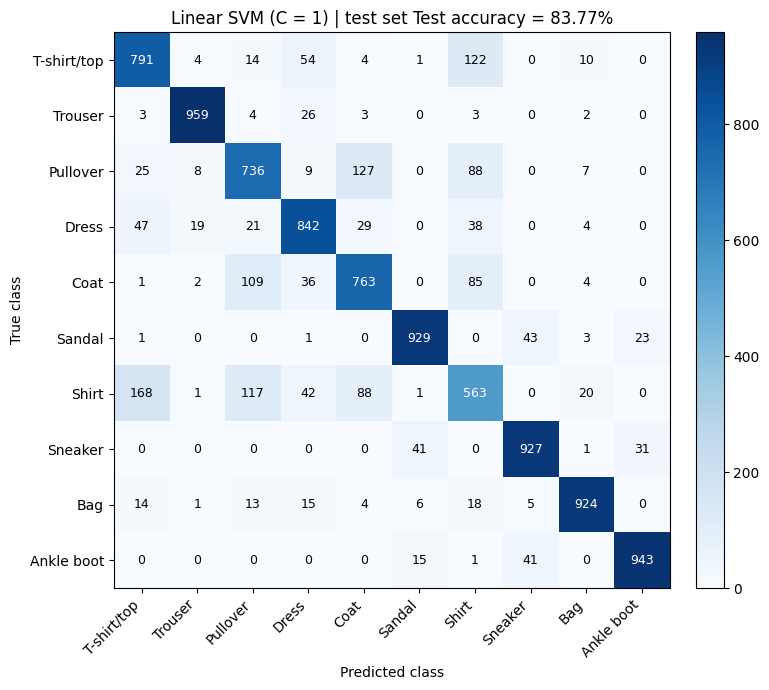

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
best_c_value = 1

os.makedirs("coding_results/b", exist_ok=True)
t0 = time.time()
clf = SVC(kernel="linear", C=best_c_value, max_iter=20000) 
fit_s = time.time() - t0

clf.fit(X_train, y_train)
train_acc = float(clf.score(X_train, y_train))
test_acc = float(clf.score(X_test, y_test))
n_support_vectors = int(clf.n_support_.sum())

y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

with open(f"coding_results/b/{best_c_value}_results.json", "w") as f:
    json.dump({
        "C": best_c_value,
        "fit_time": round(fit_s, 1),
        "n_support_vectors": n_support_vectors,
        "train_acc": train_acc,
        "test_acc": test_acc,
    }, f, indent=2)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Linear SVM (C = {best_c_value}) | test set Test accuracy = {100*acc:.2f}%")
thresh = cm.max() / 2
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, color="white" if cm[i, j] > thresh else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(f"coding_results/b/{best_c_value}_confusion_matrix.png", dpi=150)

c) Repeat the experiment (a) with the best C value from (a) with polynomial kernel of degree 2, 3, and 4. Compare the training, validation, testing accuracies, and the number of support vectors for differnt kernels (linear, polynomial kernel of degree 2, polynomial kernel of degree 3, and polynomial kernel of degree 4). List your observations.

In [6]:
best_c_value = 1
X_train, y_train, X_val, y_val, X_test, y_test = load_splits(DATA_DIR)
os.makedirs("coding_results/c", exist_ok=True)

poly_results = []
for deg in [2, 3, 4]:
    out_dir = f"coding_results/c/degree_{deg}"
    os.makedirs(out_dir, exist_ok=True)

    clf = SVC(kernel="poly", C=best_c_value, degree=deg, cache_size=2000)
    t0 = time.time()
    clf.fit(X_train, y_train)
    fit_s = time.time() - t0

    r = {
        "C": best_c_value,
        "degree": deg,
        "fit_time": round(fit_s, 1),
        "n_support_vectors": int(clf.n_support_.sum()),
        "train_acc": float(clf.score(X_train, y_train)),
        "val_acc": float(clf.score(X_val, y_val)),
        "test_acc": float(clf.score(X_test, y_test)),
    }
    poly_results.append(r)
    print(r, flush=True)

    with open(f"{out_dir}/results.json", "w") as f:
        json.dump(r, f, indent=2)

poly_results.sort(key=lambda r: r["degree"])
with open("coding_results/c/results_all_degrees.json", "w") as f:
    json.dump(poly_results, f, indent=2)

degrees = [r["degree"] for r in poly_results]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(degrees, [100 * r["train_acc"] for r in poly_results], "o-", label="Training")
ax.plot(degrees, [100 * r["val_acc"]   for r in poly_results], "s-", label="Validation")
ax.plot(degrees, [100 * r["test_acc"]  for r in poly_results], "^-", label="Testing")
ax.set_xticks(degrees)
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Accuracy (%)")
ax.set_title(f"Polynomial-kernel SVM (C = {best_c_value:g}): accuracy vs. degree")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("coding_results/c/accuracy_vs_degree.png", dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(degrees, [r["n_support_vectors"] for r in poly_results], "o-", color="C3")
ax.set_xticks(degrees)
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Number of support vectors")
ax.set_title(f"Polynomial-kernel SVM (C = {best_c_value:g}): support vectors vs. degree")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("coding_results/c/support_vectors_vs_degree.png", dpi=150)
plt.close(fig)

{'C': 1, 'degree': 2, 'fit_time': 97.1, 'n_support_vectors': 16875, 'train_acc': 0.8986666666666666, 'val_acc': 0.8740833333333333, 'test_acc': 0.8657}
{'C': 1, 'degree': 3, 'fit_time': 109.0, 'n_support_vectors': 16870, 'train_acc': 0.90775, 'val_acc': 0.86425, 'test_acc': 0.8581}
{'C': 1, 'degree': 4, 'fit_time': 129.3, 'n_support_vectors': 17221, 'train_acc': 0.9099791666666667, 'val_acc': 0.8456666666666667, 'test_acc': 0.842}


**Observation**

Degree 2 beats linear on validation and on test. A high degree SVM tends to overfit. That's interesting, but I don't know why !

## Question 2 
"Breast Cancer" Classifier using Decision Trees. You will use the
following dataset for this question: https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29. You will use the first 70 percent examples for training, next 10 percent examples for validation, and the last 20 percent examples for testing.

In [ ]:
!pip3 install ucimlrepo

In [10]:
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
  
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)
features = breast_cancer_wisconsin_diagnostic.data.features
targets = breast_cancer_wisconsin_diagnostic.data.targets

n = len(features)
n_train, n_val = int(0.7 * n), int(0.8 * n)
X_train, y_train = features.iloc[:n_train], targets.iloc[:n_train]
X_val, y_val = features.iloc[n_train:n_val], targets.iloc[n_train:n_val]
X_test, y_test = features.iloc[n_val:], targets.iloc[n_val:]

a) Implement the decision tree learning algorithm that we discussed in the class. The key step in the decision tree learning is choosing the next feature to split on. Implement the information gain heuristic for selecting the next feature. Please see lecture notes or https://en.wikipedia.org/wiki/ID3_algorithm for more details. Do the following to select candidate thresholds for continuous features: Sort all candidate values for feature $f$ from training data. Suppose $f_1; f_2; \dots; f_n$ is the sorted list. The candidate thresholds are chosen as $f_i + (f_{i+1} − f_i)/2$ for $i=1$ to $n$.

In [11]:
def classification(classes, feature_value):
    for i in range(len(classes)):
        lower = classes[i]["min"]
        upper = classes[i]["max"]
        if i == len(classes) - 1:
            if lower <= feature_value <= upper:
                return i
        else:
            if lower <= feature_value < upper:
                return i
    return None

def calculate_entropy(weights):
    total = sum(weights.values())
    entropy = 0
    for w in weights.values():
        if w > 0:
            p = w / total
            entropy -= p * np.log2(p)
    return entropy

def calculate_gain(weights, parent_entropy):
    total = sum(sum(labels.values()) for labels in weights.values())
    if total == 0:
        return 0.0
    conditional_entropy = 0.0
    for interval, labels in weights.items():
        interval_total = sum(labels.values())

        if interval_total > 0:
            interval_entropy = calculate_entropy(labels)
            conditional_entropy += (interval_total / total) * interval_entropy

    return parent_entropy - conditional_entropy

def build_tree(features, targets, dichotomizer=2):
    if dichotomizer < 2:
        raise ValueError("dichotomizer must be >= 2")
    
    majority_class = targets.value_counts().idxmax()
    if targets.nunique() == 1 or len(targets) < 2:
        return {"prediction": majority_class}

    parent_weights = targets.value_counts().to_dict()
    parent_entropy = calculate_entropy(parent_weights)

    best_feature = None
    best_thresholds = None
    best_gain = 0.0

    for f in features.columns:

        values = np.sort(features[f].dropna().unique())

        if len(values) < 2:
            continue

        candidates = values[:-1] + np.diff(values) / 2
        selected_thresholds = []
        current_gain = 0.0

        for _ in range(dichotomizer - 1):

            next_gain = current_gain
            next_thresholds = None

            for threshold in candidates:

                if threshold in selected_thresholds:
                    continue

                trial_thresholds = sorted(selected_thresholds + [float(threshold)])
                assignments = np.searchsorted(trial_thresholds, features[f].to_numpy(), side="left")
                counts = np.bincount(assignments, minlength=len(trial_thresholds) + 1)

                weights = {}

                for i in range(len(trial_thresholds) + 1):
                    mask = assignments == i
                    weights[i] = targets.iloc[np.flatnonzero(mask)].value_counts().to_dict()

                gain = calculate_gain(weights, parent_entropy)

                if gain > next_gain + 1e-12:
                    next_gain = gain
                    next_thresholds = trial_thresholds

            if next_thresholds is None:
                break

            selected_thresholds = next_thresholds
            current_gain = next_gain

        # Compare the best multiway split for each feature
        if current_gain > best_gain + 1e-12:
            best_gain = current_gain
            best_feature = f
            best_thresholds = selected_thresholds

    if best_feature is None:
        return {"prediction": majority_class}

    assignments = np.searchsorted(best_thresholds, features[best_feature].to_numpy(), side="left" )

    children = {}

    for i in range(len(best_thresholds) + 1):

        mask = assignments == i

        child_features = features.iloc[np.flatnonzero(mask)]
        child_targets = targets.iloc[np.flatnonzero(mask)]

        children[i] = build_tree(
            child_features,
            child_targets,
            dichotomizer=dichotomizer,
        )

    return {
        "feature": best_feature,
        "thresholds": best_thresholds,
        "gain": best_gain,
        "prediction": majority_class,
        "children": children
    }

In [13]:
def predict_one(tree, observation):

    if "children" not in tree:
        return tree["prediction"]

    feature = tree["feature"]
    thresholds = tree["thresholds"]

    child_index = np.searchsorted(thresholds, observation[feature], side="left")

    return predict_one(tree["children"][int(child_index)], observation)


def predict(tree, X):
    return np.array([predict_one(tree, row) for _, row in X.iterrows()])

In [14]:
import matplotlib.pyplot as plt

acc = {}
d = 2
tree = build_tree(X_train, y_train.iloc[:, 0], dichotomizer=d)

y_pred_test = predict(tree, X_test)
acc[d] = accuracy_score(y_test.iloc[:, 0], y_pred_test)
print(f"Dichotomizer {d}: Test accuracy = {acc[d]}")


Dichotomizer 2: Test accuracy = 0.9210526315789473


b) Run the decision tree construction algorithm on the training examples. Compute the accuracy on validation examples and testing examples.


In [15]:
d = 2
tree = build_tree(X_train, y_train.iloc[:, 0], dichotomizer=d)
y_valid_pred = predict(tree, X_val)
valid_acc = accuracy_score(y_val.iloc[:, 0], y_valid_pred)
print(f"Dichotomizer {d}: Validation accuracy = {valid_acc}")
y_test_pred = predict(tree, X_test)
test_acc = accuracy_score(y_test.iloc[:, 0], y_test_pred)
print(f"Dichotomizer {d}: Test accuracy = {test_acc}")

Dichotomizer 2: Validation accuracy = 0.9298245614035088
Dichotomizer 2: Test accuracy = 0.9210526315789473


c) Implement the decision tree pruning algorithm discussed in the class (via validation data).


There are approaches for tree prunning: pre-prunning and post-prunning. Since I already generated a full-grown tree, I intend to implement a post-pruning algorithm. The idea is simple: if I replace a sub-tree with a leaf, does it reduce the validation accuracy or not. If it does not, prune that sub-tree. This algorithm starts from bottom to up. It first examines the deepest internal nodes, and move towards the root. 

In [16]:
import copy

def prune_tree(tree, X_val, y_val):
    tree = copy.deepcopy(tree)
    if isinstance(y_val, pd.DataFrame):
        y_val = y_val.iloc[:, 0]

    if not X_val.index.equals(y_val.index):
        raise ValueError("Validation features and labels must be aligned")

    def prune_node(node, features, targets):

        # Leaf node: nothing to prune
        if "children" not in node:
            return node

        if len(targets) == 0:
            return node

        feature = node["feature"]
        thresholds = node["thresholds"]

        assignments = np.searchsorted(thresholds, features[feature].to_numpy(), side="left")

        for i in node["children"]:
            indices = np.flatnonzero(assignments == i)

            child_features = features.iloc[indices]
            child_targets = targets.iloc[indices]

            node["children"][i] = prune_node(node["children"][i], child_features, child_targets)

        subtree_predictions = predict(node, features)
        subtree_errors = np.sum(subtree_predictions != targets.to_numpy())

        leaf_prediction = node["prediction"]

        leaf_errors = np.sum(targets.to_numpy() != leaf_prediction)

        if leaf_errors <= subtree_errors:
            return {"prediction": leaf_prediction}

        return node

    return prune_node(tree, X_val, y_val)

In [17]:
print("Before pruning")
print("Validation accuracy:", accuracy_score(y_val.iloc[:, 0], predict(tree, X_val)))
print("Test accuracy:", accuracy_score(y_test.iloc[:, 0], predict(tree, X_test)))

pruned_tree = prune_tree(tree, X_val, y_val)

print("After pruning")
print("Training accuracy:", accuracy_score(y_train.iloc[:, 0], predict(pruned_tree, X_train)))
print("Validation accuracy:", accuracy_score(y_val.iloc[:, 0], predict(pruned_tree, X_val)))
print("Test accuracy:", accuracy_score(y_test.iloc[:, 0], predict(pruned_tree, X_test)))

Before pruning
Validation accuracy: 0.9298245614035088
Test accuracy: 0.9210526315789473
After pruning
Training accuracy: 0.9447236180904522
Validation accuracy: 0.9824561403508771
Test accuracy: 0.9649122807017544


d) Run the pruning algorithm on the decision tree constructed using training examples. Compute the accuracy on validation examples and testing examples. List your observations by comparing the performance of decision tree with and without pruning.

In [18]:
import copy

def prune_tree(tree, X_train, y_train):
    tree = copy.deepcopy(tree)
    if isinstance(y_train, pd.DataFrame):
        y_train = y_train.iloc[:, 0]

    if not X_train.index.equals(y_train.index):
        raise ValueError("Validation features and labels must be aligned")

    def prune_node(node, features, targets):

        # Leaf node: nothing to prune
        if "children" not in node:
            return node

        if len(targets) == 0:
            return node

        feature = node["feature"]
        thresholds = node["thresholds"]

        assignments = np.searchsorted(thresholds, features[feature].to_numpy(), side="left")

        for i in node["children"]:
            indices = np.flatnonzero(assignments == i)

            child_features = features.iloc[indices]
            child_targets = targets.iloc[indices]

            node["children"][i] = prune_node(node["children"][i], child_features, child_targets)

        subtree_predictions = predict(node, features)
        subtree_errors = np.sum(subtree_predictions != targets.to_numpy())

        leaf_prediction = node["prediction"]

        leaf_errors = np.sum(targets.to_numpy() != leaf_prediction)

        if leaf_errors <= subtree_errors:
            return {"prediction": leaf_prediction}

        return node

    return prune_node(tree, X_train, y_train)

In [19]:
print("Before pruning")
print("Training accuracy:", accuracy_score(y_train.iloc[:, 0], predict(tree, X_train)))
print("Validation accuracy:", accuracy_score(y_val.iloc[:, 0], predict(tree, X_val)))
print("Test accuracy:", accuracy_score(y_test.iloc[:, 0], predict(tree, X_test)))

pruned_tree = prune_tree(tree, X_val, y_val)

print("After pruning")
print("Training accuracy:", accuracy_score(y_train.iloc[:, 0], predict(pruned_tree, X_train)))
print("Validation accuracy:", accuracy_score(y_val.iloc[:, 0], predict(pruned_tree, X_val)))
print("Test accuracy:", accuracy_score(y_test.iloc[:, 0], predict(pruned_tree, X_test)))

Before pruning
Training accuracy: 1.0
Validation accuracy: 0.9298245614035088
Test accuracy: 0.9210526315789473
After pruning
Training accuracy: 0.9447236180904522
Validation accuracy: 0.9824561403508771
Test accuracy: 0.9649122807017544


** Observation **

The unprunned tree overfits because it gets 100% accuracy on training but 93% on validation and 92% on testing. However, after prunning, test accuracy improved at the cost of slight decrease in the accuracy of the training. The gap between the accuracy of trainnig and testing is gone after prunning. 